In [23]:
import numpy as np
import pandas as pd
import rasterio as rio
from scipy.ndimage import distance_transform_edt
from matplotlib import pyplot as plt
from tqdm import tqdm
import os, re
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score
import joblib
from pathlib import Path
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, cohen_kappa_score
from scipy.stats import spearmanr

In [24]:
names = locals()

In [25]:
ROOT = Path.cwd().parent
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
FEATURE_DIR = RESULTS / "features"

In [ ]:
region_mask = rio.open(RESULTS / 'region-masks' / 'region-mask-1km.tif').read(1)

In [ ]:
feature_list_1km = dict({
    'elevation': FEATURE_DIR / 'elevation-1km.tif',
    'slope':     FEATURE_DIR / 'slope-1km.tif', 
    'population': RESULTS / 'population-raster' / 'population-2020-1km.tif',
    'accessibility': FEATURE_DIR / 'accessibility-1km.tif',
    'D2water': FEATURE_DIR / 'distance-to-water-1km.tif', 
    'forest': FEATURE_DIR / 'forest-2020-1km.tif',
    'cropland': FEATURE_DIR / 'cropland-2019-1km.tif', 
    'water': FEATURE_DIR / 'water-mask-1km.tif', 
    'su': FEATURE_DIR / 'su-1km.tif',
    'vb': FEATURE_DIR / 'vb-1km.tif',
    'ss': FEATURE_DIR / 'ss-1km.tif',
    'pb': FEATURE_DIR / 'pb-1km.tif',
    'sm': FEATURE_DIR / 'sm-1km.tif', 
    'sc': FEATURE_DIR / 'sc-1km.tif', 
    'va': FEATURE_DIR / 'va-1km.tif',
    'mt': FEATURE_DIR / 'mt-1km.tif',
    'pa': FEATURE_DIR / 'pa-1km.tif',
    'vi': FEATURE_DIR / 'vi-1km.tif',
    'wb': FEATURE_DIR / 'wb-1km.tif',
    'py': FEATURE_DIR / 'py-1km.tif',
    'pi': FEATURE_DIR / 'pi-1km.tif',
    'ev': FEATURE_DIR / 'ev-1km.tif',
    'nd': FEATURE_DIR / 'nd-1km.tif', 
    'ig': FEATURE_DIR / 'ig-1km.tif', 
    'PA_Ia': RESULTS / 'protected-area-rasters' / 'protected-area-Ia-mask.tif',
    'PA_Ib': RESULTS / 'protected-area-rasters' / 'protected-area-Ib-mask.tif',
    'PA_II': RESULTS / 'protected-area-rasters' / 'protected-area-II-mask.tif',
    'PA_III': RESULTS / 'protected-area-rasters' / 'protected-area-III-mask.tif',
    'PA_IV': RESULTS / 'protected-area-rasters' / 'protected-area-IV-mask.tif',
    'PA_V': RESULTS / 'protected-area-rasters' / 'protected-area-V-mask.tif',
    'PA_VI': RESULTS / 'protected-area-rasters' / 'protected-area-VI-mask.tif',
    'urban': FEATURE_DIR / 'urban-area-2020-1km.tif',
    'bare': FEATURE_DIR / 'bare-land-2020-1km.tif',
    'building_stock': FEATURE_DIR / 'building-mineral-stock-1km.tif',
})

In [28]:
def compile_samples_for_region(
    the_region,
    selected_features,
    res='1km',
    buffer_min_km=30,          # was 50 — narrower min lets us include more candidates
    buffer_max_km=300,         # was 100 — wider ring captures broader environmental gradient
    far_fraction=0.7,          # 70% from buffer ring, 30% from country background
    pa_ratio=3,                # n_pseudo per country = 3 × n_presence (no 1:1 cap)
    min_presences_per_country=5,
    seed=42,
    verbose=False,
):
    """
    Two-tier pseudo-absence sampling for a given region.
      Tier 1 (far_fraction): buffer ring [buffer_min_km, buffer_max_km] from any presence.
      Tier 2 (1 - far_fraction): country background outside the min buffer.
      Tier 1 shortfall is automatically topped up from Tier 2.
    Returns: X, Y, country_ids, region_ids, bbox, region_mask, value_mask, log_df
    """
    rng = np.random.default_rng(seed + the_region)

    region_mask_  = rio.open(RESULTS / 'region-masks' / f'region-mask-{res}.tif')
    country_rast_ = rio.open(RESULTS / 'country-rasters' / f'state-raster-eck4-{res}.tif')
    global_quarry_area = rio.open(RESULTS / 'quarry-area-rasters' / f'global-aggregate-quarry-area-raster-eck4-{res}.tif').read(1)

    region_full   = region_mask_.read(1)
    country_full  = country_rast_.read(1)
    feature_list  = names[f'feature_list_{res}']

    # --- Window the region ---
    rr = np.where(region_full == the_region)
    i_1, i_2 = np.min(rr[0]), np.max(rr[0])
    j_1, j_2 = np.min(rr[1]), np.max(rr[1])
    a_window = ((i_1, i_2), (j_1, j_2))

    presence_raw   = global_quarry_area[i_1:i_2, j_1:j_2]
    region_mask    = (region_full[i_1:i_2, j_1:j_2] == the_region)
    country_mask_w = country_full[i_1:i_2, j_1:j_2]
    presence_in_region = np.where(
        region_mask & (presence_raw > 0), 1, 0
    ).astype(np.uint8)

    # --- Distance transform & buffer in pixels ---
    r = int(re.findall(r'\d+', res)[0])
    D_min, D_max = buffer_min_km // r, buffer_max_km // r
    distance_from_quarry = distance_transform_edt(presence_in_region == 0)

    pseudoabs = np.zeros_like(presence_in_region, dtype=np.uint8)
    log_records = []

    country_ids = np.unique(country_mask_w[region_mask])
    country_ids = country_ids[country_ids > 0]

    for cid in tqdm(country_ids, desc=f'Region {the_region}', disable=not verbose):
        country_local = (country_mask_w == cid) & region_mask  # KEY: restrict to region
        presence_local = (presence_in_region == 1) & country_local
        n_pres = int(presence_local.sum())

        if n_pres < min_presences_per_country:
            continue

        n_target = pa_ratio * n_pres
        n_far_target  = int(round(far_fraction * n_target))
        n_near_target = n_target - n_far_target

        # ---- Tier 1: buffer ring ----
        far_idx = np.where(
            (distance_from_quarry >= D_min) &
            (distance_from_quarry <= D_max) &
            country_local &
            (presence_in_region == 0) &
            (pseudoabs == 0)
        )
        n_far_avail = len(far_idx[0])
        n_far = min(n_far_target, n_far_avail)
        if n_far > 0:
            sel = rng.choice(n_far_avail, size=n_far, replace=False)
            pseudoabs[far_idx[0][sel], far_idx[1][sel]] = 1

        # ---- Tier 2: country background (outside min buffer) ----
        deficit = n_far_target - n_far
        n_near_request = n_near_target + deficit

        bg_idx = np.where(
            country_local &
            (presence_in_region == 0) &
            (pseudoabs == 0) &
            (distance_from_quarry >= D_min)
        )
        n_bg_avail = len(bg_idx[0])
        n_near = min(n_near_request, n_bg_avail)
        if n_near > 0:
            sel = rng.choice(n_bg_avail, size=n_near, replace=False)
            pseudoabs[bg_idx[0][sel], bg_idx[1][sel]] = 1

        log_records.append({
            'region': the_region, 'country': int(cid),
            'n_presence': n_pres,
            'n_pseudo_far': n_far, 'n_pseudo_near': n_near,
            'n_pseudo_total': n_far + n_near,
            'ratio_pseudo_to_presence': (n_far + n_near) / n_pres,
        })

    # --- Build labels & feature matrix ---
    label_mask  = (presence_in_region == 1) | (pseudoabs == 1)
    label_array = np.where(
        presence_in_region == 1, 1,
        np.where(pseudoabs == 1, 0, np.nan)
    ).astype(np.float32)

    feature_values = []
    for feat in selected_features:
        src = rio.open(feature_list[feat])
        gg  = src.read(1, window=a_window)
        feature_values.append(gg[label_mask])

    Y_ = label_array[label_mask]
    X_ = np.array(feature_values).T
    valid = ~np.isnan(X_).any(axis=1)
    X = X_[valid]
    Y = Y_[valid]

    country_ids_arr = country_mask_w[label_mask][valid]
    region_ids_arr  = np.full(len(Y), the_region, dtype=np.int16)

    vm = np.where(label_mask)
    value_mask = (vm[0][valid], vm[1][valid])

    log_df = pd.DataFrame(log_records)
    return X, Y, country_ids_arr, region_ids_arr, (i_1, i_2, j_1, j_2), region_mask, value_mask, log_df

In [29]:
selected_features = ['elevation', 'slope', 'population', 'accessibility', 'D2water', 'forest', 'cropland', 'water', 'su', 'vb', 'ss', 'pb', 'sm', 'sc', 'va', 'mt', 'pa', 'vi', 'wb', 'py', 'pi', 'ev', 'nd', 'ig', 'PA_Ia', 'PA_Ib', 'PA_II', 'PA_III', 'PA_IV', 'PA_V', 'PA_VI', 'urban', 'bare', 'building_stock']
print(len(selected_features)) 

34


In [ ]:
X_list, Y_list, country_list, region_list, log_list = [], [], [], [], []

for region_id in tqdm(range(1, 16), desc='Compiling regions'):
    X_r, Y_r, c_r, r_r, *_ , log_r = compile_samples_for_region(
        region_id, selected_features, res='1km', verbose=False
    )
    X_list.append(X_r); Y_list.append(Y_r)
    country_list.append(c_r); region_list.append(r_r)
    log_list.append(log_r)

X_global       = np.vstack(X_list)
Y_global       = np.concatenate(Y_list)
country_global = np.concatenate(country_list)
region_global  = np.concatenate(region_list)

# Unique group ID for GroupKFold (avoids country-ID collisions across regions)
group_global = np.array([f'{r}_{c}' for r, c in zip(region_global, country_global)])

# Add region as one-hot (recommended over integer for sklearn RF)
region_oh = pd.get_dummies(pd.Series(region_global, name='region'), prefix='reg').values
X_global_full = np.hstack([X_global, region_oh])

feature_names_full = list(selected_features) + [f'reg_{i}' for i in sorted(np.unique(region_global))]

print(f'Total samples: {len(Y_global):,}')
print(f'  Presences:        {int(Y_global.sum()):,}')
print(f'  Pseudo-absences:  {int((Y_global == 0).sum()):,}')
print(f'  Pseudo:Presence:  {(Y_global == 0).sum() / Y_global.sum():.2f}')
print(f'  Unique groups (region_country) for CV: {len(np.unique(group_global))}')
print(f'  Feature dim: {X_global_full.shape[1]} ({len(selected_features)} env + {region_oh.shape[1]} region one-hot)')

Compiling regions:   7%|▋         | 1/15 [00:11<02:34, 11.07s/it]

In [17]:
EU_NA_REGIONS = [8, 14]   # Europe, Northern America
DOWNSAMPLE_LEVELS = [1.00, 0.50, 0.25, 0.10, 0.05]

In [18]:
def subsample_eu_na_presences(
    X, Y, country, region, group,
    keep_fraction,
    seed=42,
):
    """Country-level subsampling of EU+NA presences only.
    Pseudo-absences and other regions stay untouched."""
    rng = np.random.default_rng(seed)
    keep_mask = np.ones(len(Y), dtype=bool)

    for r in EU_NA_REGIONS:
        # Country IDs in this region with at least one presence
        in_region_pres = (region == r) & (Y == 1)
        countries_with_pres = np.unique(country[in_region_pres])
        n_keep = max(1, int(round(len(countries_with_pres) * keep_fraction)))
        keep_countries = rng.choice(countries_with_pres, size=n_keep, replace=False)

        # Drop presences from non-kept countries (keep their pseudo-absences)
        drop = (region == r) & (Y == 1) & ~np.isin(country, keep_countries)
        keep_mask &= ~drop

    return (X[keep_mask], Y[keep_mask], country[keep_mask],
            region[keep_mask], group[keep_mask])

In [ ]:
downsample_results = []
feature_importances_by_level = {}

# Reference: full-data feature importance for rank-correlation comparison
ref_model = joblib.load(RESULTS / 'trained-models' / 'rf-global.pkl')
ref_imp = ref_model.feature_importances_

for level in DOWNSAMPLE_LEVELS:
    print(f'\n========== Downsample level: {level*100:.0f}% of EU+NA ==========')

    X_sub, Y_sub, c_sub, r_sub, g_sub = subsample_eu_na_presences(
        X_global_full, Y_global, country_global, region_global, group_global,
        keep_fraction=level, seed=42,
    )

    print(f'  Total samples: {len(Y_sub):,}')
    print(f'  EU presences:  {((r_sub==8) & (Y_sub==1)).sum():,}')
    print(f'  NA presences:  {((r_sub==14) & (Y_sub==1)).sum():,}')

    cv = GroupKFold(n_splits=5)
    fold_records = []
    fold_imps = []

    for fold, (tr, te) in enumerate(cv.split(X_sub, Y_sub, groups=g_sub), 1):
        model = RandomForestClassifier(
            n_estimators=400, max_depth=20, min_samples_leaf=5,
            class_weight='balanced', n_jobs=-1, random_state=42,
        )
        model.fit(X_sub[tr], Y_sub[tr])
        fold_imps.append(model.feature_importances_)

        prob = model.predict_proba(X_sub[te])[:, 1]
        pred = (prob >= 0.5).astype(int)
        test_regions = r_sub[te]

        for reg in np.unique(test_regions):
            mask = test_regions == reg
            if mask.sum() < 20 or len(np.unique(Y_sub[te][mask])) < 2:
                continue
            fold_records.append({
                'level': level, 'fold': fold, 'region': int(reg),
                'auc':   roc_auc_score(Y_sub[te][mask], prob[mask]),
                'ap':    average_precision_score(Y_sub[te][mask], prob[mask]),
                'kappa': cohen_kappa_score(Y_sub[te][mask], pred[mask]),
            })

    df_level = pd.DataFrame(fold_records)
    downsample_results.append(df_level)

    mean_imp = np.mean(fold_imps, axis=0)
    feature_importances_by_level[level] = mean_imp
    rho, _ = spearmanr(ref_imp, mean_imp)

    print(f'  Mean AUC (all regions):   {df_level["auc"].mean():.3f}')
    print(f'  Mean κ   (all regions):   {df_level["kappa"].mean():.3f}')
    print(f'  Feature importance ρ vs. full model: {rho:.3f}')

ds_all = pd.concat(downsample_results, ignore_index=True)


========== Downsample level: 100% of EU+NA ==========
  Total samples: 601,390
  EU presences:  75,538
  NA presences:  37,233
  Mean AUC (all regions):   0.833
  Mean κ   (all regions):   0.442
  Feature importance ρ vs. full model: 0.999

========== Downsample level: 50% of EU+NA ==========
  Total samples: 554,083
  EU presences:  48,503
  NA presences:  16,961
  Mean AUC (all regions):   0.838
  Mean κ   (all regions):   0.435
  Feature importance ρ vs. full model: 0.990

========== Downsample level: 25% of EU+NA ==========
  Total samples: 515,603
  EU presences:  18,763
  NA presences:  8,221
  Mean AUC (all regions):   0.839
  Mean κ   (all regions):   0.420
  Feature importance ρ vs. full model: 0.972

========== Downsample level: 10% of EU+NA ==========
  Total samples: 503,743
  EU presences:  6,925
  NA presences:  8,199
  Mean AUC (all regions):   0.828
  Mean κ   (all regions):   0.402
  Feature importance ρ vs. full model: 0.957

========== Downsample level: 5% of EU+NA 

In [20]:
# Per-region κ across downsampling levels (the headline table)
pivot_kappa = (
    ds_all.groupby(['region','level'])['kappa']
    .mean().unstack('level').round(3)
)
print('Per-region κ across downsampling levels:')
print(pivot_kappa)

# Same for AUC
pivot_auc = (
    ds_all.groupby(['region','level'])['auc']
    .mean().unstack('level').round(3)
)
print('\nPer-region AUC across downsampling levels:')
print(pivot_auc)

# "Other regions" stability — drop EU and NA
non_eu_na = ds_all[~ds_all['region'].isin(EU_NA_REGIONS)]
print('\nMean κ in non-EU/NA regions, by downsampling level:')
print(non_eu_na.groupby('level')['kappa'].agg(['mean','std']).round(3))

Per-region κ across downsampling levels:
level    0.05   0.10   0.25   0.50   1.00
region                                   
1       0.400  0.544  0.495  0.541  0.527
2       0.476  0.476  0.533  0.450  0.469
3       0.412  0.430  0.452  0.488  0.383
4       0.358  0.429  0.391  0.460  0.366
5       0.315  0.330  0.337  0.289  0.282
6       0.301  0.314  0.325  0.378  0.374
7       0.357  0.418  0.421  0.474  0.525
8      -0.010  0.184  0.407  0.448  0.522
9       0.406  0.473  0.493  0.455  0.461
10      0.586  0.355  0.430  0.491  0.483
11      0.436  0.374  0.429  0.331  0.349
12      0.323  0.335  0.358  0.366  0.352
13      0.550  0.449  0.421  0.481  0.493
14      0.008  0.339  0.341  0.446  0.486
15      0.388  0.469  0.428  0.448  0.477

Per-region AUC across downsampling levels:
level    0.05   0.10   0.25   0.50   1.00
region                                   
1       0.823  0.888  0.842  0.862  0.852
2       0.859  0.855  0.876  0.858  0.842
3       0.820  0.795  0.794  0.84

In [21]:
# ---------- Prep ----------
EU_NA_REGIONS = [8, 14]
levels = sorted(ds_all['level'].unique())  # [0.05, 0.10, 0.25, 0.50, 1.00]

# Per-fold mean κ for EU+NA combined and for "other 13 regions" combined
def group_mean_per_fold(df, region_set):
    sub = df[df['region'].isin(region_set)]
    return sub.groupby(['level','fold'])['kappa'].mean().reset_index()

eu_na_per_fold = group_mean_per_fold(ds_all, EU_NA_REGIONS)
other_per_fold = group_mean_per_fold(ds_all, [r for r in range(1,16) if r not in EU_NA_REGIONS])

# Mean ± SD across folds at each level
def summarise(df):
    return df.groupby('level')['kappa'].agg(['mean','std']).reindex(levels)

eu_na_summary = summarise(eu_na_per_fold)
other_summary = summarise(other_per_fold)

# Feature importance ρ vs. full model (level=1.00 is the reference)
ref_imp = feature_importances_by_level[1.00]
rhos = {lvl: spearmanr(ref_imp, feature_importances_by_level[lvl])[0] for lvl in levels}

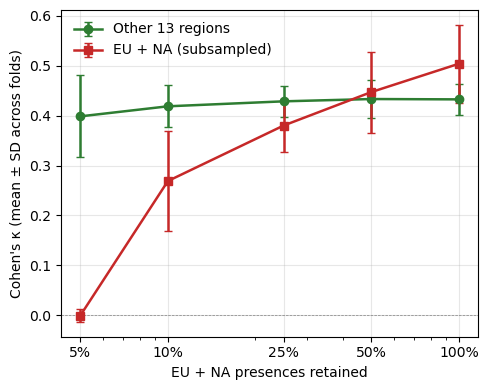

In [22]:
fig = plt.figure(figsize=(5, 4))

ax1 = plt.subplot(111)
x = np.array(levels) * 100  # convert to percentage

ax1.errorbar(x, other_summary['mean'], yerr=other_summary['std'],
            marker='o', capsize=3, lw=1.8, color='#2E7D32',
            label='Other 13 regions')
ax1.errorbar(x, eu_na_summary['mean'], yerr=eu_na_summary['std'],
            marker='s', capsize=3, lw=1.8, color='#C62828',
            label='EU + NA (subsampled)')

ax1.set_xscale('log')
ax1.set_xticks([5, 10, 25, 50, 100])
ax1.set_xticklabels(['5%', '10%', '25%', '50%', '100%'])
ax1.set_xlabel('EU + NA presences retained')
ax1.set_ylabel("Cohen's κ (mean ± SD across folds)")
ax1.axhline(0, color='gray', lw=0.5, ls='--')
ax1.legend(frameon=False, loc='best')
ax1.grid(alpha=0.3)

plt.tight_layout()
# plt.savefig(FIGURES / 'Supplementary-Figure-11.jpg', dpi=600, bbox_inches='tight')
plt.show()